In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv("Telecom_Customer_Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,InternetService,Contract,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,CUST0001,Female,0,Yes,No,1,No,DSL,Month-to-month,Electronic check,29.85,29.85,Yes
1,CUST0002,Male,0,No,No,34,Yes,DSL,One year,Mailed check,56.95,1930.30,No
2,CUST0003,Female,0,Yes,Yes,2,Yes,Fiber optic,Month-to-month,Electronic check,53.85,107.70,Yes
3,CUST0004,Male,0,No,No,45,Yes,Fiber optic,Two year,Bank transfer,42.30,1903.50,No
4,CUST0005,Male,1,Yes,No,8,Yes,DSL,Month-to-month,Electronic check,70.70,565.60,Yes


In [3]:
print("Rows and Columns:", df.shape)

Rows and Columns: (20, 13)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   customerID       20 non-null     str    
 1   gender           20 non-null     str    
 2   SeniorCitizen    20 non-null     int64  
 3   Partner          20 non-null     str    
 4   Dependents       20 non-null     str    
 5   tenure           20 non-null     int64  
 6   PhoneService     20 non-null     str    
 7   InternetService  20 non-null     str    
 8   Contract         20 non-null     str    
 9   PaymentMethod    20 non-null     str    
 10  MonthlyCharges   20 non-null     float64
 11  TotalCharges     20 non-null     float64
 12  Churn            20 non-null     str    
dtypes: float64(2), int64(2), str(9)
memory usage: 3.2 KB


In [5]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,20.000000,20.000000,20.000000,20.000000
mean,0.300000,24.000000,58.767500,1789.980000
std,0.470162,21.925712,28.664467,2218.993672
min,0.000000,1.000000,19.950000,29.850000
25%,0.000000,6.500000,30.862500,208.050000
50%,0.000000,16.500000,55.775000,728.300000
75%,1.000000,38.250000,88.425000,2241.525000
max,1.000000,70.000000,101.100000,6975.500000


In [6]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'InternetService', 'Contract',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [7]:
df.isnull().sum()

customerID         0
gender             0
SeniorCitizen      0
Partner            0
Dependents         0
tenure             0
PhoneService       0
InternetService    0
Contract           0
PaymentMethod      0
MonthlyCharges     0
TotalCharges       0
Churn              0
dtype: int64

In [8]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage.sort_values(ascending=False)

customerID         0.0
gender             0.0
SeniorCitizen      0.0
Partner            0.0
Dependents         0.0
tenure             0.0
PhoneService       0.0
InternetService    0.0
Contract           0.0
PaymentMethod      0.0
MonthlyCharges     0.0
TotalCharges       0.0
Churn              0.0
dtype: float64

In [9]:
numeric_columns = df.select_dtypes(include=np.number).columns

df[numeric_columns] = df[numeric_columns].fillna(
    df[numeric_columns].median()
)

In [10]:
categorical_columns = df.select_dtypes(
    include="object"
).columns

for column in categorical_columns:
    df[column] = df[column].fillna(
        df[column].mode()[0]
    )

C:\Users\asjun\AppData\Local\Temp\ipykernel_5588\274695633.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [11]:
df.isnull().sum()

customerID         0
gender             0
SeniorCitizen      0
Partner            0
Dependents         0
tenure             0
PhoneService       0
InternetService    0
Contract           0
PaymentMethod      0
MonthlyCharges     0
TotalCharges       0
Churn              0
dtype: int64

In [12]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [13]:
df = df.drop_duplicates()

print("Duplicate records after cleaning:", df.duplicated().sum())

Duplicate records after cleaning: 0


In [14]:
for column in categorical_columns:
    print("\n", column)
    print(df[column].unique())


 customerID
<ArrowStringArray>
['CUST0001', 'CUST0002', 'CUST0003', 'CUST0004', 'CUST0005', 'CUST0006',
 'CUST0007', 'CUST0008', 'CUST0009', 'CUST0010', 'CUST0011', 'CUST0012',
 'CUST0013', 'CUST0014', 'CUST0015', 'CUST0016', 'CUST0017', 'CUST0018',
 'CUST0019', 'CUST0020']
Length: 20, dtype: str

 gender
<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str

 Partner
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

 Dependents
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

 PhoneService
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

 InternetService
<ArrowStringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

 Contract
<ArrowStringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str

 PaymentMethod
<ArrowStringArray>
['Electronic check', 'Mailed check', 'Bank transfer', 'Credit card']
Length: 4, dtype: str

 Churn
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str


In [15]:
for column in categorical_columns:
    df[column] = df[column].astype(str).str.strip()

In [16]:
if "Gender" in df.columns:
    df["Gender"] = df["Gender"].str.title()

In [17]:
if "Churn" in df.columns:
    df["Churn"] = df["Churn"].astype(str).str.strip().str.title()

In [18]:
df.dtypes

customerID             str
gender                 str
SeniorCitizen        int64
Partner                str
Dependents             str
tenure               int64
PhoneService           str
InternetService        str
Contract               str
PaymentMethod          str
MonthlyCharges     float64
TotalCharges       float64
Churn                  str
dtype: object

In [19]:
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"],
        errors="coerce"
    )

In [20]:
df.dtypes

customerID             str
gender                 str
SeniorCitizen        int64
Partner                str
Dependents             str
tenure               int64
PhoneService           str
InternetService        str
Contract               str
PaymentMethod          str
MonthlyCharges     float64
TotalCharges       float64
Churn                  str
dtype: object

In [21]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns

for column in numeric_columns:
    
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = df[
        (df[column] < lower) |
        (df[column] > upper)
    ]
    
    print(column, "Outliers:", len(outliers))

SeniorCitizen Outliers: 0
tenure Outliers: 0
MonthlyCharges Outliers: 0
TotalCharges Outliers: 3


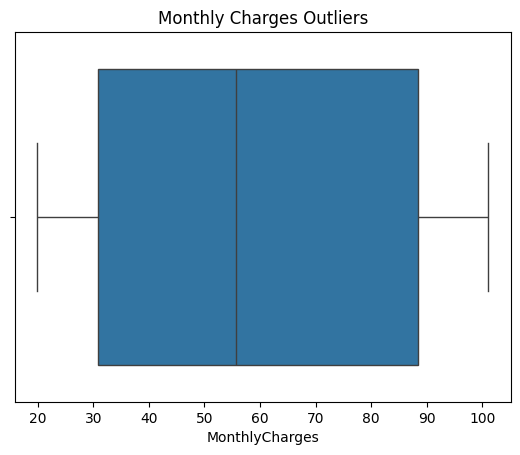

In [22]:
if "MonthlyCharges" in df.columns:
    
    sns.boxplot(x=df["MonthlyCharges"])
    
    plt.title("Monthly Charges Outliers")
    plt.show()

In [23]:
if "tenure" in df.columns:
    df["Tenure_Group"] = pd.cut(
        df["tenure"],
        bins=[0, 12, 24, 48, np.inf],
        labels=[
            "New Customer",
            "1-2 Years",
            "2-4 Years",
            "4+ Years"
        ]
    )

In [24]:
if "TotalCharges" in df.columns and "tenure" in df.columns:
    
    df["Avg_Monthly_Spend"] = (
        df["TotalCharges"] /
        df["tenure"].replace(0, np.nan)
    )
    
    df["Avg_Monthly_Spend"] = (
        df["Avg_Monthly_Spend"].fillna(0)
    )

In [25]:
if "Churn" in df.columns:
    df["Churn_Flag"] = df["Churn"].map({
        "Yes": 1,
        "No": 0
    })

In [26]:
df[["Churn", "Churn_Flag"]].head()

,Churn,Churn_Flag
0,Yes,1
1,No,0
2,Yes,1
3,No,0
4,Yes,1


In [27]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns

numeric_columns

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges',
       'Avg_Monthly_Spend', 'Churn_Flag'],
      dtype='str')

In [28]:
scaler = StandardScaler()

df_scaled = df.copy()

df_scaled[numeric_columns] = scaler.fit_transform(
    df_scaled[numeric_columns]
)

df_scaled.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,InternetService,Contract,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Tenure_Group,Avg_Monthly_Spend,Churn_Flag
0,CUST0001,Female,-0.654654,Yes,No,-1.076248,No,DSL,Month-to-month,Electronic check,-1.035035,-0.813817,Yes,New Customer,-1.034697,1.224745
1,CUST0002,Male,-0.654654,No,No,0.467934,Yes,DSL,One year,Mailed check,-0.065053,0.064879,No,2-4 Years,-0.071052,-0.816497
2,CUST0003,Female,-0.654654,Yes,Yes,-1.029455,Yes,Fiber optic,Month-to-month,Electronic check,-0.176011,-0.777822,Yes,New Customer,-0.175691,1.224745
3,CUST0004,Male,-0.654654,No,No,0.982661,Yes,Fiber optic,Two year,Bank transfer,-0.589416,0.052487,No,2-4 Years,-0.589088,-0.816497
4,CUST0005,Male,1.527525,Yes,No,-0.748694,Yes,DSL,Month-to-month,Electronic check,0.427096,-0.566107,Yes,New Customer,0.427403,1.224745


In [29]:
X = df.drop(columns=["Churn", "Churn_Flag"], errors="ignore")

y = df["Churn_Flag"]

In [30]:
print("Features:", X.shape)
print("Target:", y.shape)

Features: (20, 14)
Target: (20,)


In [31]:
X = pd.get_dummies(
    X,
    drop_first=True
)

X.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Avg_Monthly_Spend,customerID_CUST0002,customerID_CUST0003,customerID_CUST0004,customerID_CUST0005,customerID_CUST0006,...,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card,PaymentMethod_Electronic check,PaymentMethod_Mailed check,Tenure_Group_1-2 Years,Tenure_Group_2-4 Years,Tenure_Group_4+ Years
0,0,1,29.85,29.85,29.850000,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
1,0,34,56.95,1930.30,56.773529,True,False,False,False,False,...,False,False,True,False,False,False,True,False,True,False
2,0,2,53.85,107.70,53.850000,False,True,False,False,False,...,True,False,False,False,False,True,False,False,False,False
3,0,45,42.30,1903.50,42.300000,False,False,True,False,False,...,True,False,False,True,False,False,False,False,True,False
4,1,8,70.70,565.60,70.700000,False,False,False,True,False,...,False,False,False,False,False,True,False,False,False,False


In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [33]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16, 38)
Testing data: (4, 38)


In [34]:
df.to_csv(
    "Telecom_Customer_Churn_Cleaned.csv",
    index=False
)

print("Cleaned dataset exported successfully.")

Cleaned dataset exported successfully.
